# 4 - Linear Regression

**Purpose:** train our first learned forecasting model, then compare its errors with persistence on the **same training and validation examples**.

The task, selected space, 30-minute horizon, five-minute measurement-age rule and chronological periods are unchanged. This notebook does not open the final-test CSV or choose the final winning model.


### Import the tools and shared functions


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression
from IPython.display import display

project_root = Path("..").resolve()
assert (project_root / "src" / "evaluation.py").is_file(), "Check the project root and file placement."
assert (project_root / "src" / "features.py").is_file(), "Copy the new src/features.py into the project."
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.evaluation import persistence_predict, regression_metrics
from src.features import make_features, INPUT_COLUMNS

print("Project root:", project_root)
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)

Project root: C:\Users\chris\OneDrive\Desktop\MMA3001\Project\mma3001_project
Python: 3.14.6 | scikit-learn: 1.9.1


### Load the same training and validation data

In [2]:
space_prefix = "227f1068"
data_folder = project_root / "data" / "prepared" / space_prefix
with open(data_folder / "preparation_settings.json", encoding="utf-8") as file:
    settings = json.load(file)

feature_columns = settings["feature_columns"]
target_column = settings["target_column"]
assert feature_columns == INPUT_COLUMNS
assert target_column == "target_headcount"
assert settings["space_id"].startswith(space_prefix)
assert settings["horizon_minutes"] == 30

train = pd.read_csv(data_folder / "train.csv")
validation = pd.read_csv(data_folder / "validation.csv")
datasets = {"train": train, "validation": validation}
periods = {
    "train": (settings["train_start"], settings["validation_start"]),
    "validation": (settings["validation_start"], settings["test_start"])
}
fingerprints = {}

for name, dataset in datasets.items():
    for column in ["forecast_time", "target_time", "target_headcount_observed_at"]:
        dataset[column] = pd.to_datetime(dataset[column], utc=True)
    period_start, period_end = periods[name]
    assert len(dataset) == settings["split_counts"][name]
    assert len(dataset) > 0
    assert dataset["forecast_time"].is_unique
    assert dataset["forecast_time"].is_monotonic_increasing
    assert np.isfinite(dataset[feature_columns + [target_column]].to_numpy(dtype=float)).all()
    assert (dataset["forecast_time"] >= pd.Timestamp(period_start)).all()
    assert (dataset["target_time"] < pd.Timestamp(period_end)).all()
    assert ((dataset["target_time"] - dataset["forecast_time"]) == pd.Timedelta(minutes=30)).all()
    fingerprints[name] = hashlib.sha256((data_folder / f"{name}.csv").read_bytes()).hexdigest()
    print(f"{name}: {len(dataset):,} examples checked")

baseline_record = project_root / "outputs" / space_prefix / "persistence" / "run_information.json"
if baseline_record.is_file():
    with open(baseline_record, encoding="utf-8") as file:
        baseline_information = json.load(file)
    assert fingerprints == baseline_information["csv_sha256"], "Prepared files differ from Notebook 3. Investigate before comparing."
    print("Prepared files match the saved baseline run.")

print("The final-test CSV has not been opened.")

train: 14,772 examples checked
validation: 3,388 examples checked
Prepared files match the saved baseline run.
The final-test CSV has not been opened.


### Represent time and weekday sensibly

The model still receives the **same five kinds of information**. Encoding changes their numerical representation, not the information available:

| Agreed input | Numerical representation |
|---|---|
| Current count and counts 15/30 minutes earlier | Three unchanged count columns |
| Time of day | Two numbers representing a position around a 24-hour clock |
| Day of week | Six yes/no columns for Tuesday through Sunday; Monday is the reference |

For clock time $h$ in decimal hours:

$$x_{\rm sin}=\sin(2\pi h/24),\qquad x_{\rm cos}=\cos(2\pi h/24).$$

Why both? Together they identify the time around a circle, so 23:59 and 00:01 are close rather than at opposite ends of a number line. This gives a linear model a smooth daily pattern. **One sine/cosine pair does not describe every possible occupancy pattern**, especially several separate daily peaks.




In [3]:
X_train = make_features(train)
X_validation = make_features(validation)
y_train = train[target_column].to_numpy(dtype=float)
y_validation = validation[target_column].to_numpy(dtype=float)

assert X_train.index.equals(train.index)
assert X_validation.index.equals(validation.index)
assert list(X_train.columns) == list(X_validation.columns)
assert target_column not in X_train.columns

print("Training input table shape:", X_train.shape)
print("Validation input table shape:", X_validation.shape)
print("Encoded columns:", list(X_train.columns))
display(X_train.head())

Training input table shape: (14772, 11)
Validation input table shape: (3388, 11)
Encoded columns: ['headcount_now', 'headcount_lag15', 'headcount_lag30', 'time_sin', 'time_cos', 'is_tuesday', 'is_wednesday', 'is_thursday', 'is_friday', 'is_saturday', 'is_sunday']


,headcount_now,headcount_lag15,headcount_lag30,time_sin,time_cos,is_tuesday,is_wednesday,is_thursday,is_friday,is_saturday,is_sunday
0,1.0,1.0,1.0,-0.866025,-0.500000,0.0,0.0,0.0,0.0,0.0,1.0
1,1.0,0.0,1.0,-0.965926,-0.258819,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,1.0,-0.991445,-0.130526,0.0,0.0,0.0,0.0,0.0,1.0
3,1.0,0.0,1.0,0.707107,-0.707107,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,1.0,0.0,0.659346,-0.751840,0.0,0.0,0.0,0.0,0.0,0.0


### Fit the model using training examples only


In [4]:
model = LinearRegression()
started = perf_counter()
model.fit(X_train, y_train)
fit_seconds = perf_counter() - started

coefficients = pd.DataFrame({
    "encoded_input": X_train.columns,
    "coefficient": model.coef_
})
print("Intercept:", model.intercept_)
print("Fitting time (seconds):", fit_seconds)
print("Training matrix rank:", model.rank_, "of", X_train.shape[1], "encoded columns")
display(coefficients)

Intercept: 0.5711353147650895
Fitting time (seconds): 0.03459379996638745
Training matrix rank: 11 of 11 encoded columns


,encoded_input,coefficient
0,headcount_now,0.389601
1,headcount_lag15,0.141346
2,headcount_lag30,0.146365
3,time_sin,-0.022053
4,time_cos,-0.386281
5,is_tuesday,-0.097713
6,is_wednesday,-0.087230
7,is_thursday,-0.014325
8,is_friday,-0.168281
9,is_saturday,-0.304935


### Predict and compare with persistence


In [5]:
encoded_by_split = {"train": X_train, "validation": X_validation}
result_rows = []
predictions_by_split = {}

for name, dataset in datasets.items():
    predicted = model.predict(encoded_by_split[name])
    observed = dataset[target_column].to_numpy(dtype=float)
    baseline_predicted = persistence_predict(dataset["headcount_now"].to_numpy())

    for model_name, forecast in [("persistence", baseline_predicted), ("linear_regression", predicted)]:
        scores = regression_metrics(observed, forecast)
        result_rows.append({
            "model": model_name,
            "split": name,
            "examples": len(dataset),
            "mae_people": scores["mae"],
            "rmse_people": scores["rmse"]
        })

    predictions = dataset[["forecast_time", "target_time", "target_headcount_observed_at"]].copy()
    predictions["observed_headcount"] = observed
    predictions["predicted_headcount"] = predicted
    predictions["residual_people"] = observed - predicted
    predictions_by_split[name] = predictions

comparison = pd.DataFrame(result_rows)
metrics = comparison[comparison["model"] == "linear_regression"].copy()
display(comparison.round(4))

validation_scores = comparison[comparison["split"] == "validation"].set_index("model")
mae_change_percent = 100 * (
    validation_scores.loc["persistence", "mae_people"]
    - validation_scores.loc["linear_regression", "mae_people"]
) / validation_scores.loc["persistence", "mae_people"]
print("Validation MAE reduction relative to persistence (%):", round(mae_change_percent, 2))
print("Positive means lower error; this is not a percentage accuracy score.")

,model,split,examples,mae_people,rmse_people
0,persistence,train,14772,1.2557,2.1709
1,linear_regression,train,14772,1.1611,1.8564
2,persistence,validation,3388,0.8628,1.4057
3,linear_regression,validation,3388,0.8218,1.1647


Validation MAE reduction relative to persistence (%): 4.75
Positive means lower error; this is not a percentage accuracy score.


### Check output limitations and error direction

In [6]:
quality_rows = []
for name, predictions in predictions_by_split.items():
    predicted = predictions["predicted_headcount"]
    residuals = predictions["residual_people"]
    quality_rows.append({
        "split": name,
        "negative_predictions": int((predicted < 0).sum()),
        "negative_percent": 100 * (predicted < 0).mean(),
        "minimum_prediction": predicted.min(),
        "mean_residual_people": residuals.mean(),
        "underprediction_percent": 100 * (residuals > 0).mean(),
        "overprediction_percent": 100 * (residuals < 0).mean()
    })
quality_summary = pd.DataFrame(quality_rows)
display(quality_summary.round(4))

range_rows = []
for column in feature_columns[:3]:
    lower = train[column].min()
    upper = train[column].max()
    outside = (validation[column] < lower) | (validation[column] > upper)
    range_rows.append({
        "input": column, "training_min": lower, "training_max": upper,
        "validation_rows_outside_range": int(outside.sum())
    })
range_summary = pd.DataFrame(range_rows)
display(range_summary)

,split,negative_predictions,negative_percent,minimum_prediction,mean_residual_people,underprediction_percent,overprediction_percent
0,train,114,0.7717,-0.1366,-0.0000,41.2266,58.7734
1,validation,27,0.7969,-0.1360,-0.1207,40.7615,59.2385


,input,training_min,training_max,validation_rows_outside_range
0,headcount_now,0.0,32.0,0
1,headcount_lag15,0.0,32.0,0
2,headcount_lag30,0.0,32.0,0


### Measure prediction time

In [7]:
model.predict(X_validation)
encoded_batch_times = []
end_to_end_batch_times = []

for repeat in range(5):
    started = perf_counter()
    for batch in range(100):
        model.predict(X_validation)
    encoded_batch_times.append((perf_counter() - started) / 100)

    started = perf_counter()
    for batch in range(100):
        model.predict(make_features(validation))
    end_to_end_batch_times.append((perf_counter() - started) / 100)

median_seconds = float(np.median(encoded_batch_times))
timing = pd.DataFrame([{
    "model": "linear_regression",
    "split": "validation",
    "examples_per_batch": len(validation),
    "fit_seconds": fit_seconds,
    "median_batch_seconds": median_seconds,
    "microseconds_per_example": median_seconds / len(validation) * 1_000_000,
    "feature_encoding_plus_predict_batch_seconds": float(np.median(end_to_end_batch_times)),
    "repeats": 5,
    "batches_per_repeat": 100
}])
display(timing)

,model,split,examples_per_batch,fit_seconds,median_batch_seconds,microseconds_per_example,feature_encoding_plus_predict_batch_seconds,repeats,batches_per_repeat
0,linear_regression,validation,3388,0.034594,0.000462,0.136243,0.00324,5,100


### Inspect the same validation week as Notebook 3


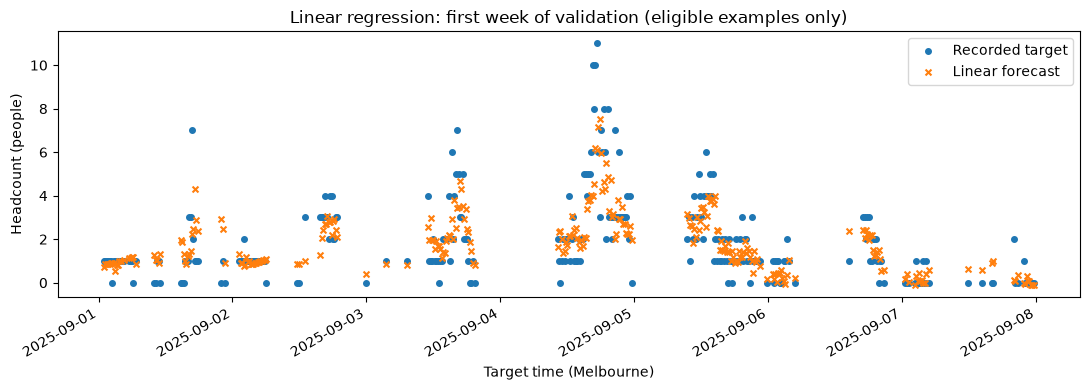

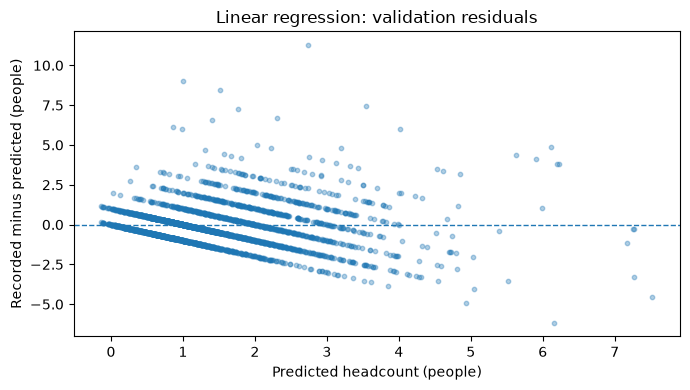

In [8]:
validation_predictions = predictions_by_split["validation"]
week_start = pd.Timestamp(settings["validation_start"])
week_end = week_start + pd.Timedelta(days=7)
plot_data = validation_predictions[
    (validation_predictions["target_time"] >= week_start)
    & (validation_predictions["target_time"] < week_end)
]
plot_times = plot_data["target_time"].dt.tz_convert("Australia/Melbourne")

week_fig, ax = plt.subplots(figsize=(11, 4))
ax.scatter(plot_times, plot_data["observed_headcount"], s=16, label="Recorded target")
ax.scatter(plot_times, plot_data["predicted_headcount"], s=18, marker="x", label="Linear forecast")
ax.set_title("Linear regression: first week of validation (eligible examples only)")
ax.set_xlabel("Target time (Melbourne)")
ax.set_ylabel("Headcount (people)")
ax.legend()
week_fig.autofmt_xdate()
week_fig.tight_layout()
plt.show()

residual_fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(validation_predictions["predicted_headcount"], validation_predictions["residual_people"], s=10, alpha=0.35)
ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title("Linear regression: validation residuals")
ax.set_xlabel("Predicted headcount (people)")
ax.set_ylabel("Recorded minus predicted (people)")
residual_fig.tight_layout()
plt.show()

### Save the model development evidence

In [9]:
output_folder = project_root / "outputs" / space_prefix / "linear_regression"
output_folder.mkdir(parents=True, exist_ok=True)
metrics.to_csv(output_folder / "metrics.csv", index=False)
comparison.to_csv(output_folder / "comparison_with_persistence.csv", index=False)
coefficients.to_csv(output_folder / "coefficients.csv", index=False)
quality_summary.to_csv(output_folder / "prediction_checks.csv", index=False)
range_summary.to_csv(output_folder / "validation_input_ranges.csv", index=False)
timing.to_csv(output_folder / "timing.csv", index=False)
for name, predictions in predictions_by_split.items():
    predictions.to_csv(output_folder / f"{name}_predictions.csv", index=False)
week_fig.savefig(output_folder / "validation_first_week.png", dpi=160, bbox_inches="tight")
residual_fig.savefig(output_folder / "validation_residuals.png", dpi=160, bbox_inches="tight")

run_information = {
    "model": "linear_regression",
    "estimator": "sklearn.linear_model.LinearRegression",
    "estimator_parameters": model.get_params(),
    "training_objective": "ordinary least squares; minimise training residual sum of squares",
    "fit_partitions": ["train"],
    "evaluated_partitions": list(datasets),
    "test_data_used": False,
    "space_id": settings["space_id"],
    "horizon_minutes": settings["horizon_minutes"],
    "input_columns": feature_columns,
    "encoded_columns": list(X_train.columns),
    "encoding": "three raw counts; sine/cosine of hour/24; Tue-Sun indicators with Monday reference",
    "encoding_source_sha256": hashlib.sha256((project_root / "src" / "features.py").read_bytes()).hexdigest(),
    "scaling": "none for this ordinary least-squares model",
    "output_policy": "raw fractional predictions; no rounding, clipping or coefficient sign constraint",
    "intercept": float(model.intercept_),
    "coefficients": {column: float(value) for column, value in zip(X_train.columns, model.coef_)},
    "training_matrix_rank": int(model.rank_),
    "csv_sha256": fingerprints,
    "preparation_settings": settings,
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "scikit_learn_version": sklearn.__version__,
    "timing_scope": "predict on encoded validation table; encoding-plus-predict also reported; file IO excluded"
}
with open(output_folder / "run_information.json", "w", encoding="utf-8") as file:
    json.dump(run_information, file, indent=2)
print("Saved linear-regression evidence to:", output_folder)
print("The final-test CSV was not opened or evaluated.")

Saved linear-regression evidence to: C:\Users\chris\OneDrive\Desktop\MMA3001\Project\mma3001_project\outputs\227f1068\linear_regression
The final-test CSV was not opened or evaluated.
